# Laboratoire de programmation mathématique 2 :<br/> Itérez-moi! <span style="color:silver">(systèmes dynamiques discrets)</span>

Où nous explorerons ce qui se passe si nous continuons à répéter la même chose.

## La méthode de Newton

La méthode de Newton est un algorithme pour trouver les racines (zéros) d'une fonction $f:\mathbb{R}\to\mathbb{R}$. Elle est expliquée par cette image:

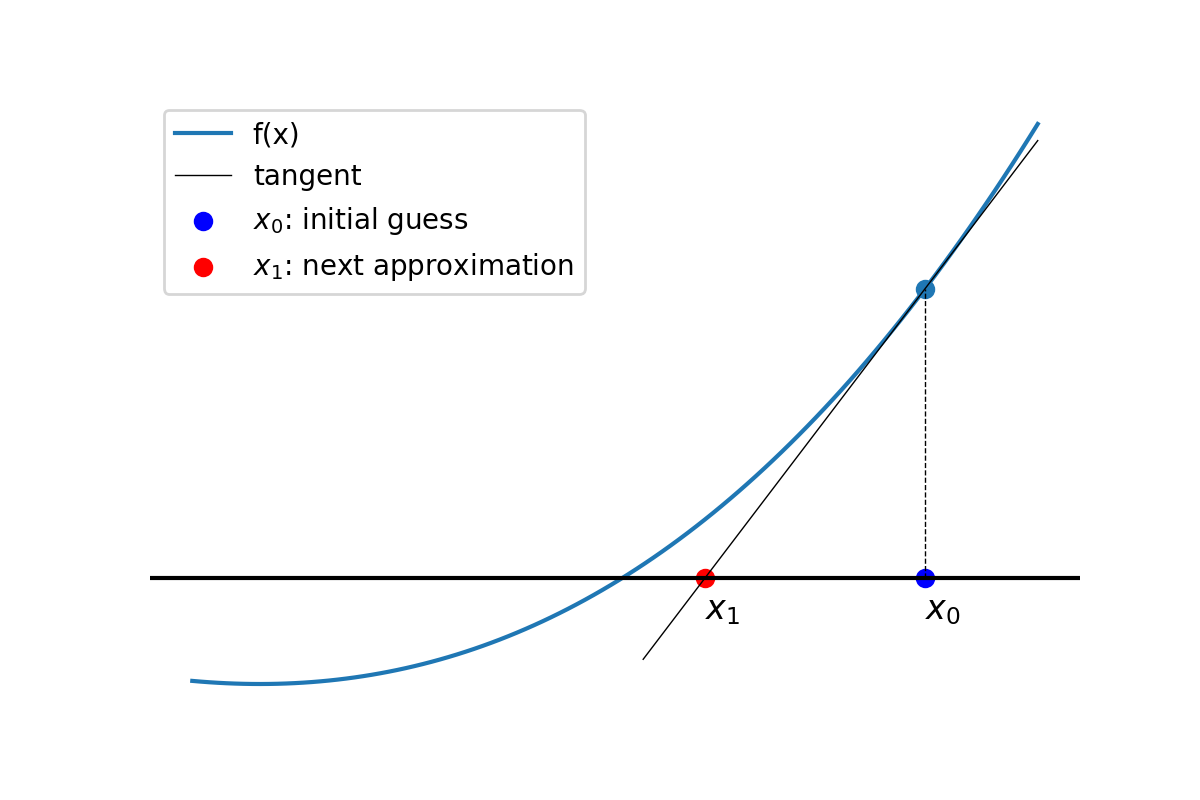




En mots: Nous commençons à un certain point $x_0\in\mathbb{R}$, notre estimation initiale d'une racine de $f$. Nous calculons ensuite une racine approximative améliorée
$$x_1 = x_0 -\frac{f(x_0)}{f'(x_0)}.$$
Pour obtenir des approximations encore meilleures, nous itérons la procédure: nous calculons $x_2$ à partir de $x_1$, $x_3$ à partir de $x_2$, etc.

<div style="border: 1px solid gold; padding: 5px">

**Exercice:**

- Écrivez une fonction python `newton_step(x0, f, fp)` qui calcule $x_1$ à partir du triplet $x_0$ (noté `x0`), $f$ (noté `f`) et $f'$ (noté `fp`).
- Utilisez-la pour trouver une racine de $f(x)=x^3 - 2x^2 - 5x + 7$: commencez par $x_0=4$, itérez 10 fois (vous devrez implémenter à la fois $f$ et $f'$ comme fonctions python). Vérifiez que $f(x)$ est très proche de 0 au $x$ que vous avez trouvé.
</div>

In [3]:
import numpy as np
import matplotlib.pyplot as plt

def f(x):
        
        return x**3-2*x**2-5*x+7
    
def fp(x):
        
        return 3*x**2-4*x-5
    
def newton_steps(x, f, fp):

        x = x - fp(x)/f(x)
    
        return x
    
x = 4.0

for i in range(10):
        x = newton_steps(x, f, fp)
        print(f"Itération {i+1} : x = {x}")


Itération 1 : x = 2.5789473684210527
Itération 2 : x = 4.847401829586447
Itération 3 : x = 3.919215917214612
Itération 4 : x = 2.4145633635312587
Itération 5 : x = 3.4809188018630035
Itération 6 : x = 1.169498816320984
Itération 7 : x = 336.86759708300013
Itération 8 : x = 336.8586735151104
Itération 9 : x = 336.84974971034416
Itération 10 : x = 336.8408256686825


### Vers quelle racine convergeons-nous?

La fonction $f$ peut avoir plusieurs racines. Si nous choisissons $x_0$, la méthode de Newton ne nous en donne qu'une seule. Explorons laquelle (pour la fonction $f(x)=x^3 - 2x^2 - 5x + 7$ que nous avons utilisée ci-dessus) - c'est assez surprenant!

<div style="border: 1px solid gold; padding: 5px">

**Exercice:**

- Tracez le graphique de $f$ pour $-2\leq x\leq 4$ pour voir à quoi ressemble $f$ et où elle a des racines (astuce: utilisez `plt.grid()` pour voir les lignes de la grille)
- Implémentez une fonction `draw_xn(n, xmin, xmax)`, qui trace le graphique de $x_n$ en fonction de $x_0$, pour $x_0\in[x_{min}, x_{max}]$. (Astuce: ajoutez `plt.ylim(-3, 4)` à votre code - cela limite l'axe des $y$ à l'intervalle $[-3,4]$.)
- Exécutez `draw_xn(100, -2, 4)`. Nous voyons maintenant vers laquelle des 3 racines la méthode de Newton converge, en fonction de $x_0$. Il y a un comportement bosselé autour de $x_0=-0.3$ et $x_0=2$. Zoomez sur l'un de ces points - par exemple, exécutez `draw_xn(100, 1.95, 2)`. Voyez ce qui se passe et zoomez à nouveau - le motif se répète indéfiniment.
</div>

> La ligne `%config InlineBackend.figure_format = 'retina'` demande à Jupyter (notre environnement de programmation) d'afficher des images nettes (en haute résolution). (Cela est particulièrement utile pour bien voir les détails des courbes et des petits symboles mathématiques.)

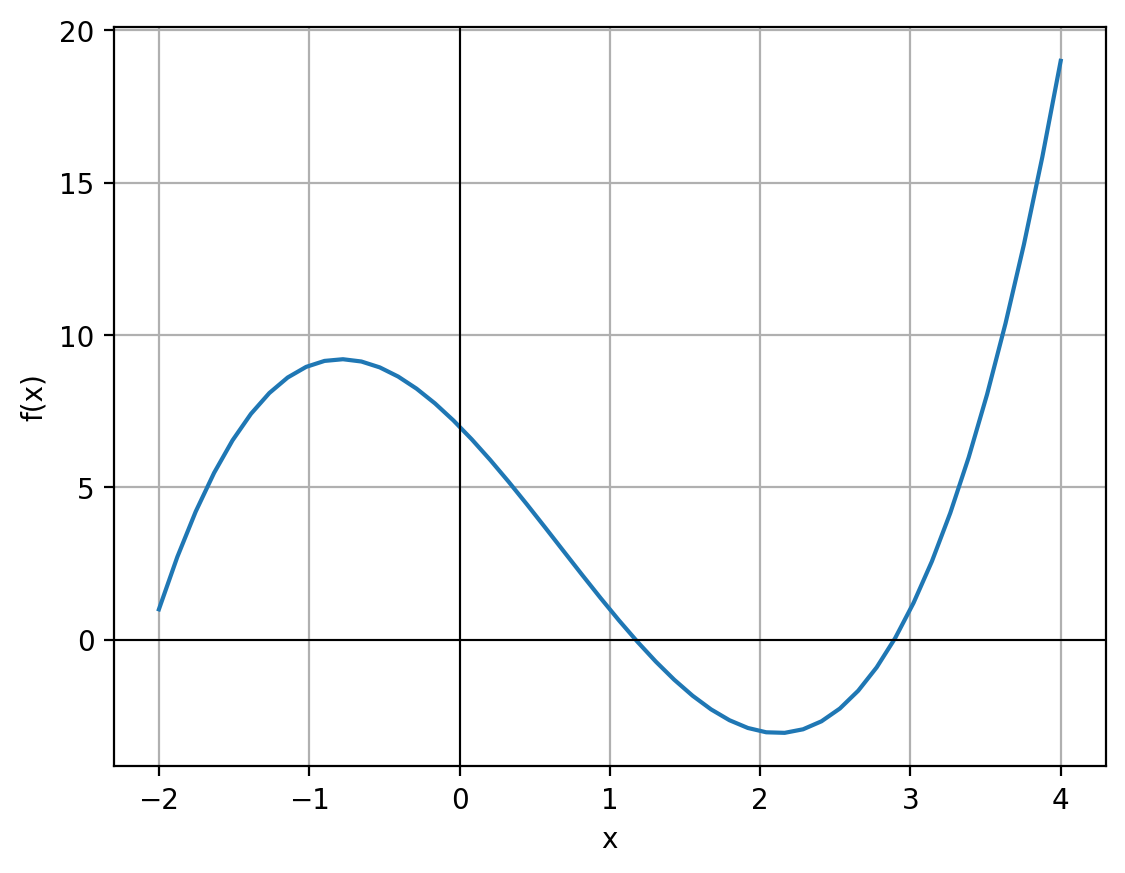

In [ ]:
%config InlineBackend.figure_format = 'retina'

x = np.linspace(-2, 4)

plt.plot(x, f(x))
plt.grid()
plt.xlabel('x')
plt.ylabel('f(x)')
plt.axhline(0, color = 'black', linewidth = 0.75)
plt.axvline(0, color = 'black', linewidth = 0.75)
#plt.show() but I don't need it here because I'm working with a Jupyter Notebook.

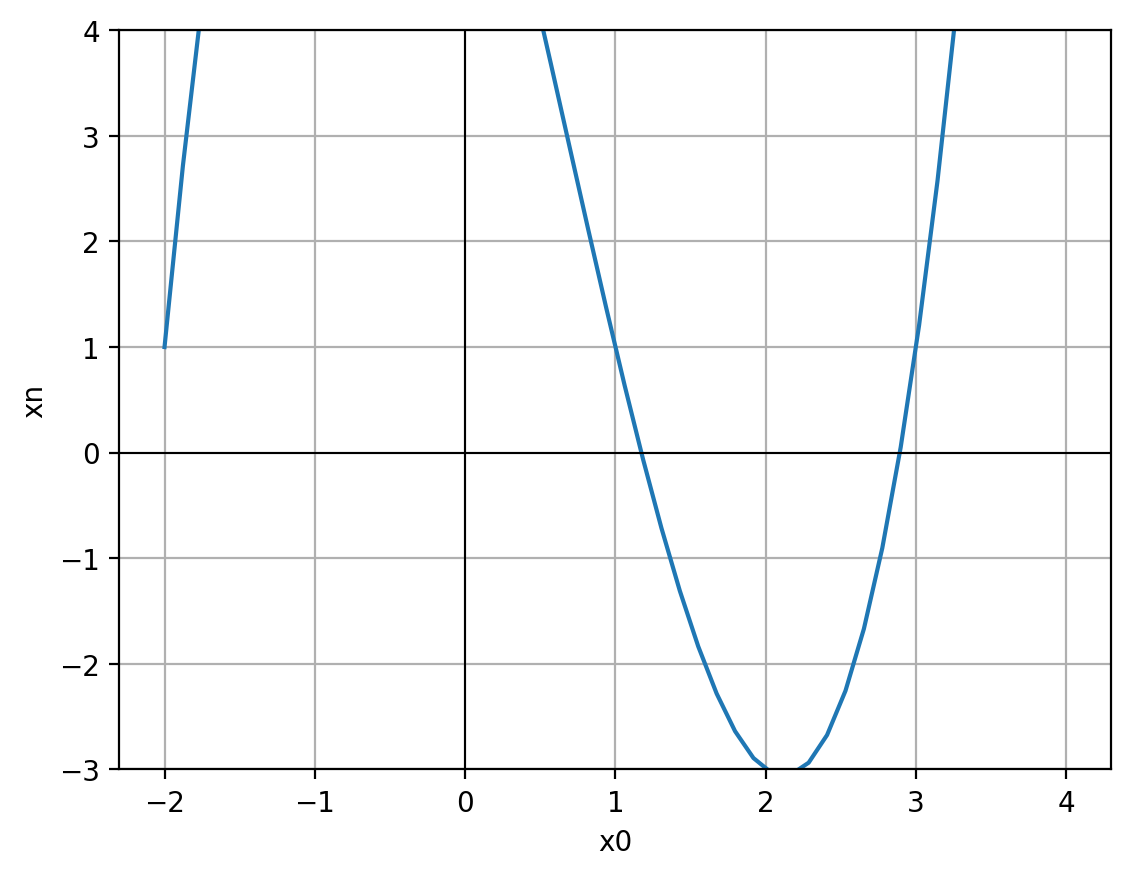

In [37]:
def draw_xn(n, xmin, xmax):

    x0 =np.linspace(xmin, xmax)
    xn = f(x0)
    plt.ylim(-3, 4)
    
    plt.plot(x0, xn)
    plt.grid()
    plt.xlabel("x0")
    plt.ylabel("xn")
    plt.axhline(0, color ='black', linewidth = 0.75)
    plt.axvline(0, color = 'black', linewidth = 0.75)

draw_xn(100, -2, 4)

## Application logistique: dynamique simple, comportement compliqué


Choisissons un paramètre $r\in[0,4]$ et itérons l'_application logistique_ $x\mapsto r x (1-x)$, $x\in[0,1]$.

> L'application logistique est un modèle simple pour l'évolution de la population d'une espèce au fil du temps. Si $x_n$ est la population de l'année $n$ (normalisée entre 0 et 1), alors $x_{n+1} = r x_n (1-x_n)$ est la population de l'année $n+1$. Le coefficient $r$ contrôle le taux de reproduction et le terme $(1-x_n)$ modélise l'influence de la surpopulation.
>
> _Pourquoi étudier l'application logistique? En faisant augmenter le paramètre $r$, le système révèle une riche gamme  de comportements : équilibres stables, cycles finis, bifurcations par doublement de période, chaos, cycles finis de nouveau, etc. L'application logistique est simple, mais cette progression de l'ordre vers le chaos à travers des transitions de phase distinctes se produit également dans des systèmes dynamiques plus réalistes et complexes Elle peut donc servir comme un modèle de ces systèmes plus complexes._

<div style="border: 1px solid gold; padding: 5px">

**Exercice :**

Créez une visualisation montrant comment la séquence ${x_n}$ évolue au fil du temps pour trois valeurs différentes de $r$ : 2.5, 3.5 et 4.0.

Pour chaque valeur de $r$ :
- Choisissez $x_0$ aléatoirement dans $[0,1]$ en utilisant `np.random.random()`
- Créez une liste contenant les valeurs $x_0, x_1, x_2, \ldots, x_{99}$
- Tracez cette séquence
</div>

**Astuces Python :**
 - Pour créer une liste vide, utilisez `[]`
 - Pour ajouter une valeur à une liste `lst`, utilisez `lst.append(valeur)`
 - Pour tracer des points sans lignes de connexion, utilisez `plt.plot(x, '.')`
 - Si vous préférez les tableaux numpy plutôt que les listes, vous pouvez initialiser un tableau de zéros avec `np.zeros(100)`

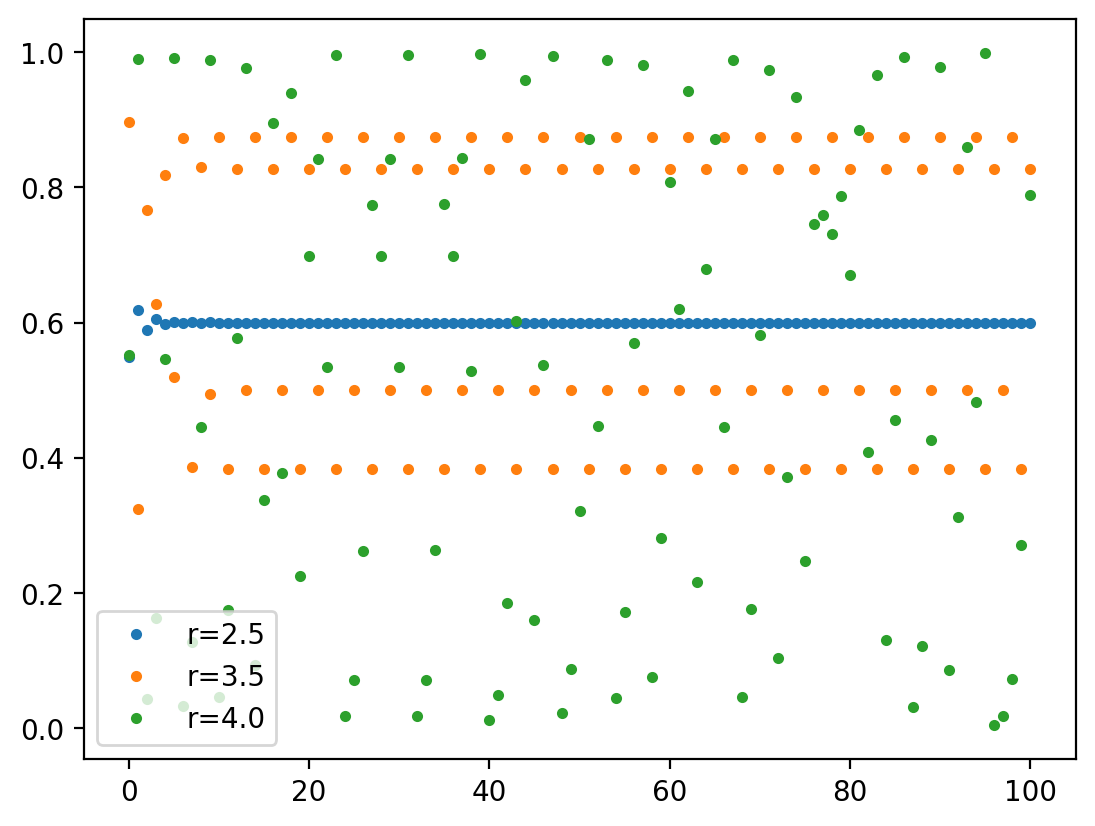

In [ ]:
def f(x, r):
    return r*x*(1-x)

r = [2.5, 3.5, 4.0]

for e in r:
    x0 = np.random.random()
    lst = []

    lst.append(x0)

    for i in range(100):
        x = f(x0, e)
        lst.append(x)
        x0 = x
        
    plt.plot(lst, '.', label =f'r={e}')

plt.legend()
plt.show()




### Diagramme de bifurcation : visualisation du comportement à long terme
Que se passe-t-il ? Vous avez peut-être remarqué que :
- Pour certaines valeurs de $r$, la séquence ${x_n}$ converge vers une valeur unique
- Pour d'autres valeurs, la séquence commence à osciller entre plusieurs valeurs
- Pour certaines valeurs (comme $r=4$), la séquence ne se stabilise pas, bien qu'elle visite certains endroits plus fréquemment que d'autres

Un *diagramme de bifurcation* nous aide à visualiser ce qui se produit à travers différentes valeurs de $r$. Il fonctionne comme suit :

Pour chaque valeur de $r$ dans une plage :
 - Commencer avec un $x_0$ aléatoire
 - Itérer la fonction $x\mapsto r x (1-x)$ plusieurs fois ($N_1$ itérations) pour éliminer le comportement transitoire, c'est-à-dire pour permettre au système de se stabiliser
 - Continuer à itérer encore $N_2$ fois (pour un grand $N_2$), en traçant chaque valeur $x_n$ en fonction de $r$

> Pourquoi des valeurs initiales aléatoires ? Bien que $x_0=0$ donne toujours la séquence sans intérêt $x_n=0$ pour tout $n$, presque toute autre valeur initiale conduira au même comportement à long terme pour un $r$ donné. L'utilisation de valeurs aléatoires nous aide à éviter ces cas particuliers.




<div style="border: 1px solid gold; padding: 5px">

**Exercice :**

Complétez la fonction Python `bifurcation_diagram(r_min, r_max, r_steps, N_1, N_2)` qui :

 - Crée un tableau de valeurs $r$ de $r_{min}$ à $r_{max}$ avec r_steps points
 - Crée un tableau de valeurs initiales aléatoires $x_0$ (une pour chaque $r$)
 - Pour chaque $r$ :
   - Itère l'application $N_1$ fois pour éliminer les transitoires (sans tracer)
   - Itère $N_2$ fois supplémentaires, en traçant chaque point $(r, x_n)$

Exécutez `bifurcation_diagram(2, 4, 10000, 1000, 1000)` pour voir le comportement à long terme pour chaque $r\in[2, 4]$. Vous verrez que pour les petites valeurs de $r$, il n'y a qu'un seul point limite, puis nous en obtenons 2, puis 4, etc., et ensuite nous obtenons un comportement plutôt étrange. Remplacez $2$ par $3.5$ pour zoomer sur la partie intéressante, puis zoomez à nouveau sur n'importe quelle partie que vous trouvez intéressante.
</div>

**Astuces Python :**
- Créez un tableau de valeurs `r` en utilisant : `r = np.linspace(r_min, r_max, r_steps)`
- Créez un tableau de valeurs initiales aléatoires en utilisant : `x = np.random.random(r_steps)` 
- Les deux phases  d'itérations :
  - D'abord, itérez `N_1` fois sans traçage (pour ignorer les transitoires)
    ```python
    x = r * x * (1 - x)
    ````
  - Itérez `N_2` fois supplémentaires, en tracant (r, x) actuel
    ```python
    x = r * x * (1 - x)  
    plt.plot(r, x, ',k', alpha=0.1)  # Traçage de l'état actuel
    ```
    L'option `',k'` crée de petits points noirs, et `alpha=0.1` les rend partiellement transparents
- Si travailler avec des tableaux est nouveau pour vous : Les opérations NumPy fonctionnent sur des tableaux entiers à la fois, donc `r * x * (1 - x)` multiplie les éléments correspondants (le tableau `x` a la même longueur que `r`, chaque position correspondant à une valeur de `r`)







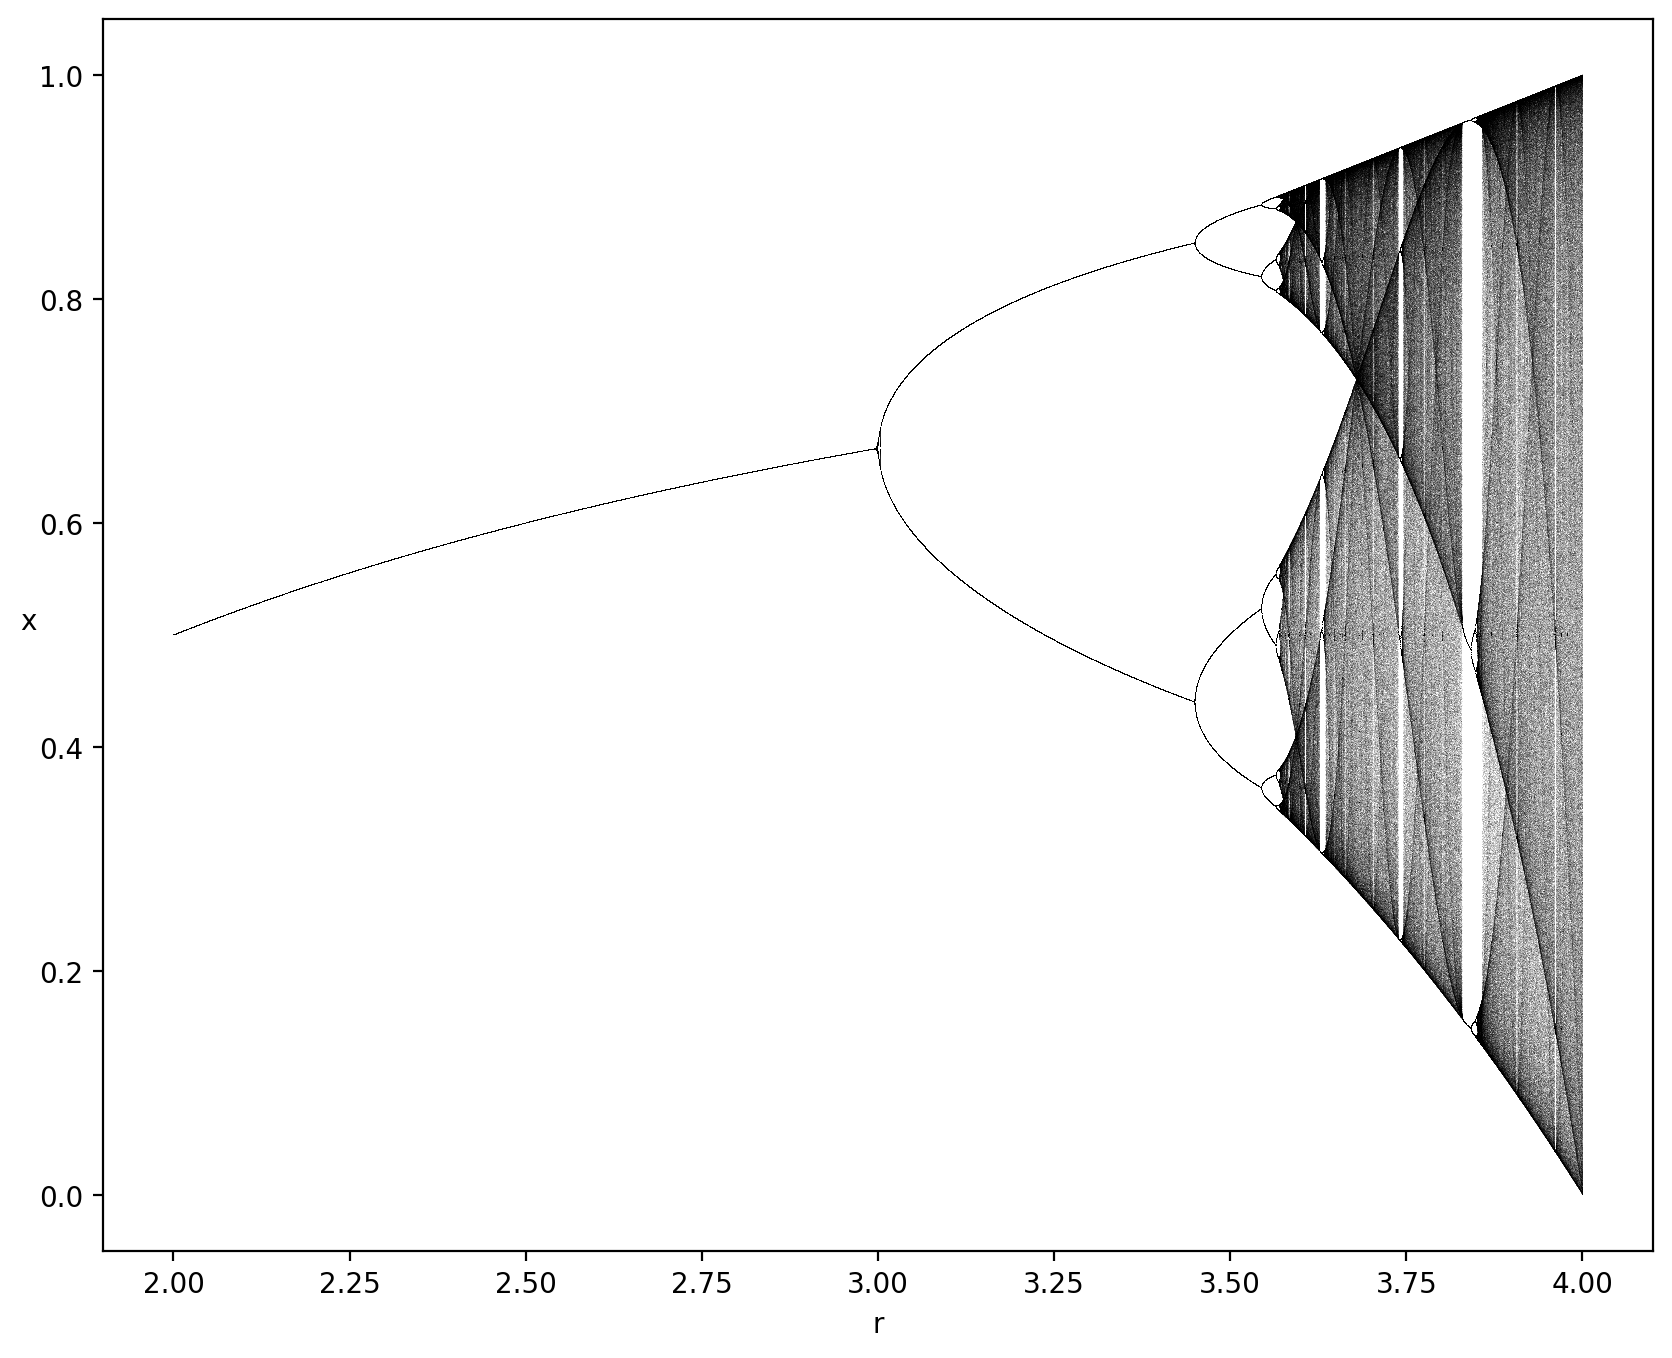

In [56]:
def bifurcation_diagram(r_min, r_max, r_steps, N_1, N_2):
    # agrandir l'image et indiquer les axes
    plt.figure(figsize=(10, 8))
    plt.xlabel('r')
    plt.ylabel('x', rotation=0)

    ### COMPLÉTEZ LA FONCTION

    r = np.linspace(r_min, r_max, r_steps)

    x = np.random.random(r_steps)

    for i in range(N_1):
        x = r*x*(1-x)
    
    for i in range(N_2):
        x = r*x*(1-x)

        plt.plot(r, x, ',k', alpha=0.1)
    
    plt.show()

bifurcation_diagram(2, 4, 10000, 1000, 1000)

### Comportement chaotique et exposants de Lyapunov

Fixons un $r\in[0,4]$, choisissons $x_0\in[0,1]$, et commençons notre itération
$$x_0\mapsto x_1\mapsto x_2\mapsto x_3\mapsto\dots$$ Si nous commençons à un autre $\tilde x_0\in[0,1]$, qui est très proche de $x_0$, les $\tilde x_n$ sont-ils proches des $x_n$ pour tous les $n$, ou bien dérivent-ils?

<div style="border: 1px solid gold; padding: 5px">

**Exercice:**

Essayez avec $r=4$, un $x_0\in[0,1]$ aléatoire et $\tilde x_0=x_0 + 10^{-10}$ (pour écrire $10^{-10}$ en python, vous pouvez utiliser `1e-10` ou `10**(-10)`). Tracez les suites $x_n$ et $\tilde x_n$ pour $n\leq 50$ (mettez `plt.show()` seulement à la fin)
</div>

In [ ]:
### ÉCRIVEZ ICI




Comme nous le voyons, même une très petite différence, comme $10^{-10}$, peut s'amplifier avec le temps (au moins pour $r=4$ - nous étudierons bientôt d'autres valeurs de $r$ !). Un tel comportement est appelé *chaotique* et il apparaît dans de nombreux autres "systèmes dynamiques" (par exemple, il nous empêche d'avoir des prévisions météorologiques à long terme).

Comment pouvons-nous comprendre plus précisément ce qui se passe ? _Un peu plus de mathématiques que d'habitude !_

Pour notre application logistique $f(x) = rx(1-x)$, lorsque deux points $x_n$ et $\tilde{x}_n$ sont très proches :

1. La différence entre leurs valeurs suivantes peut être approximée en utilisant la dérivée :
   $\tilde{x}_{n+1} - x_{n+1} \approx f'(x_n) \cdot (\tilde{x}_n - x_n)$

2. En suivant cela de manière récursive, après $n$ itérations :
   $|\tilde{x}_n - x_n| \approx |f'(x_{n-1})| \cdot |f'(x_{n-2})| \cdot ... \cdot |f'(x_0)| \cdot |\tilde{x}_0 - x_0|$

3. Prendre le logarithme nous donne une somme plutôt qu'un produit :
   $$\log|\tilde{x}_n - x_n| \approx \log|f'(x_{n-1})| + \log|f'(x_{n-2})| + ... + \log|f'(x_0)| + \log|\tilde{x}_0 - x_0|$$

4. L'exposant de Lyapunov $\lambda$ est défini comme la limite des moyens
   $$\lambda = \lim_{n\to\infty}\frac{\log|f'(x_{n-1})| + \log|f'(x_{n-2})| + ... + \log|f'(x_0)|}{n}$$
   Pour le calculer approximativement, nous utiliserons la formule
   $$\lambda \approx \frac{1}{N_2}\sum_{k=N_1}^{N_1+N_2-1} \log|f'(x_k)|$$

Si $\lambda > 0$, les trajectoires voisines divergent exponentiellement ("chaos").\
Si $\lambda < 0$, les trajectoires voisines convergent (stabilité).\
Si $\lambda = 0$, le système est à un point de bifurcation.

<div style="border: 1px solid gold; padding: 5px">

**Exercice:**

Écrivez une fonction python `lyapunov(r, N_1, N_2)` qui calcule $\lambda$ (tel que donné par la formule ci-dessus) pour $f(x) = rx(1-x)$. Choisissez $x_0\in[0,1]$ au hasard en utilisant `np.random.random()`. Pour obtenir la valeur absolue, utilisez `np.abs()`, pour le logarithme `np.log()`.

> `lambda` est un mot-clé python, vous ne pouvez donc pas l'utiliser comme nom de variable

Ensuite, exécutez la fonction (déjà écrite) `plot_lyapunov` pour voir le graphique de $\lambda(r)$; où $\lambda(r)>0$, notre système est "chaotique". Vous pouvez zoomer sur n'importe quel intervalle de $r$ que vous trouvez intéressant. Essayez de comparer ce que vous voyez sur la graphe de $\lambda$ avec ce que vous avez vu sur de diagramme de bifurcation.
</div>

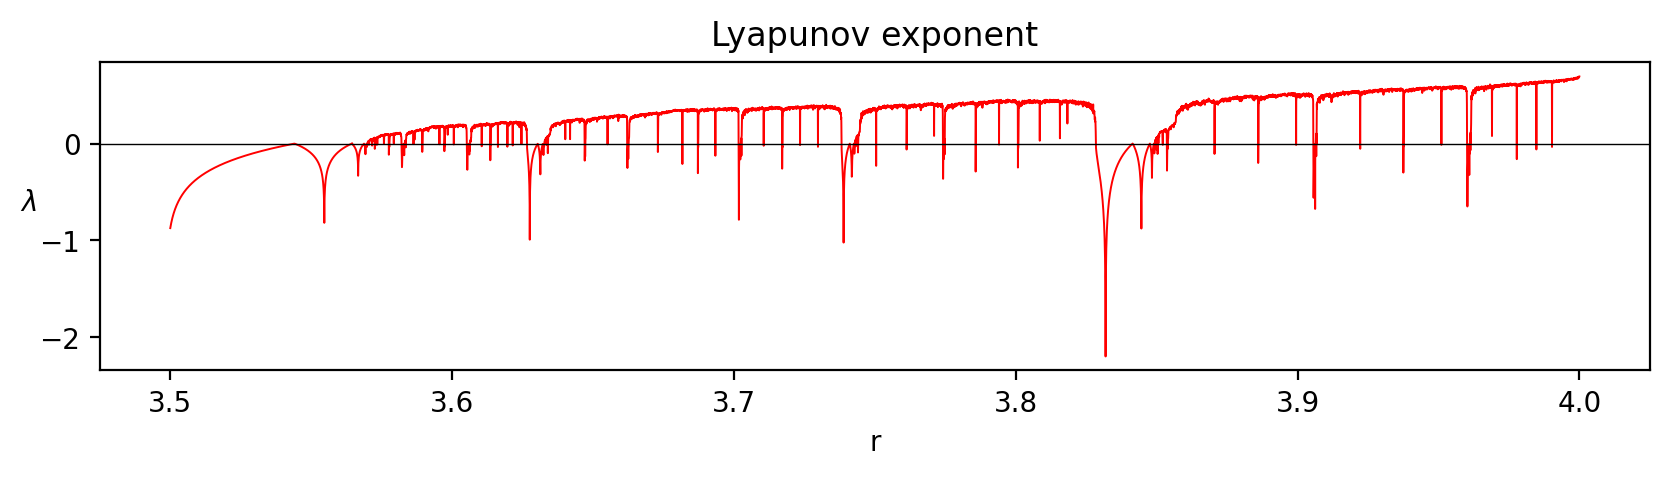

In [57]:

def lyapunov(r, N_1, N_2):
    x = np.random.random()

    for i in range(N_1):
        x = r*x*(1-x)

    somme_lyap = 0
    for i in range(N_2):
        derivee = r*(1-2*x)
        somme_lyap += np.log(np.abs(derivee))

        x = r*x*(1-x)
    
    return somme_lyap/N_2

### ÉCRIVEZ AU-DESSUS DE CETTE LIGNE

def plot_lyapunov(r_min, r_max, r_steps, N_1, N_2):
    r_tot = np.linspace(r_min, r_max, r_steps)
    lamb_tot = lyapunov(r_tot, N_1, N_2)
    plt.figure(figsize=(10,2))
    plt.plot(r_tot, lamb_tot, linewidth=0.7, color='r')
    plt.axhline(0, color='black', linewidth=0.5)  # Add a horizontal line at 0
    plt.xlabel('r')
    plt.ylabel(r'$\lambda$', rotation=0)
    plt.title('Lyapunov exponent')
    plt.show()

plot_lyapunov(r_min=3.5, r_max=4, r_steps=10000, N_1=1000, N_2=2000)

Il est instructif de compare ce graph (et les endoits où $\lambda$ est positive ou négative) avec le diagramme de bifurcation.

### Les ensembles de Julia à nouveau, mais plus beaux !

Apprenons d'abord quelques astuces de numpy supplémentaires. Exécutez le code ci-dessous et voyez ce qu'il fait:

In [ ]:
x = np.random.rand(10)
print('x:', x)

y = (x < 0.5)
print('y:', y)

# Lorsqu'on commence à additionner, True devient 1 et False devient 0
print('Combien de fois "True" ?', np.sum(y))

z = np.zeros(10)

for _ in range(10):
    x = np.random.random(10)
    z += (x < 0.5)  # à nouveau True devient 1 et False 0
print('z:', z)

Nous allons maintenant voir ce que produit l'itération de $z\mapsto r z (1-z)$ lorsque nous permettons à $z$ et $r$ d'être des nombres complexes. Les images qui en résultent sont assez étonnantes !

Nous voulons voir pour quelles valeurs de $z_0$ la séquence $z_n$ tend vers l'infini et à quelle vitesse cela se produit.

<div style="border: 1px solid gold; padding: 5px">

**Exercice :**

Complétez le code dans la cellule ci-dessous : Pour chaque $z=z_0$ (dans le tableau `z`), déterminez combien de fois nous avons $|z_n| < 5$ (une fois que $|z_n| \geq 5$, la séquence tend vers l'infini très rapidement). Stockez ces entiers dans le tableau `steps` de taille N × N, qui contient initialement des zéros partout.
</div>

Les parties sombres de l'image sont les $z_0$ pour lesquels les itérations tendent vers l'infini très rapidement (`steps` est petit), les parties les plus claires sont les $z_0$ pour lesquels les itérations restent bornées (`steps` est 200) - cette partie est appelée un *ensemble de Julia*.

In [63]:
N = 1000

# créer le tableau z de nombres complexes
x = np.linspace(0, 1, N)
y = np.linspace(-0.5, 0.5, N)
x, y = np.meshgrid(x, y)
z = x + y * 1j

# choisir un r particulier
r = 3.05 + 0.15j

# créer un tableau de zéros - la valeur initiale de steps
steps = np.zeros([N, N])

# itérer z -> rz(1-z) 200 fois et changer steps
for _ in range(200):

    ### ÉCRIVEZ EN DESSOUS DE CETTE LIGNE   <-----

    for i in range(200):

        steps += (np.abs(z)<5)

        z = r*z*(1-z)
    
    ### ÉCRIVEZ AU-DESSUS DE CETTE LIGNE    <-----

    
plt.figure(figsize=(10, 10)) # créer une grande image
plt.pcolormesh(x, y, steps, cmap = 'magma')   # créer la carte de chaleur du tableau d'ensemble de Julia
plt.axis('scaled') # la même échelle pour les axes
plt.show()

C:\Users\sarah\AppData\Local\Temp\ipykernel_10400\122866780.py:24: RuntimeWarning: overflow encountered in multiply
  z = r*z*(1-z)
C:\Users\sarah\AppData\Local\Temp\ipykernel_10400\122866780.py:24: RuntimeWarning: invalid value encountered in multiply
  z = r*z*(1-z)


KeyboardInterrupt: 

## Ensemble de Mandelbrot

C'est l'une des images mathématiques les plus emblématiques. Elle est similaire à l'ensemble de Julia que vous venez de produire, avec une petite modification:

Pour chaque $z$ (un nombre complexe), nous créons maintenant une suite $w_n$ via $w_0=0$ et $w_{n+1} = w_n^2 + z$. L'ensemble de Mandelbrot est constitué des $z$ pour lesquels la suite $w_n$ est bornée. Pour obtenir une image colorée (comme c'est généralement le cas), nous colorons ensuite les $z$ restants en fonction du nombre d'étapes nécessaires jusqu'à ce que $w_n$ devienne très grand (par exemple $|w_n|>100$).

<div style="border: 1px solid gold; padding: 5px">

**Exercice:**

Copiez le code que vous avez écrit pour l'ensemble de Julia et modifiez-le pour qu'il dessine l'ensemble de Mandelbrot.
>Quelques paramètres recommandés: Utilisez des nombres complexes $z=x+iy$ avec $x\in[-1.5, 0.5]$ et $y\in[-1,1]$. Au lieu de tracer le nombre d'étapes, tracez le logarithme du nombre d'étapes - cela rend l'image plus belle. Augmentez le nombre d'itérations à au moins 500.

Après avoir vu l'ensemble de Mandelbrot en entier, zoomez sur n'importe quelle région que vous trouvez intéressante.
</div>

C:\Users\sarah\AppData\Local\Temp\ipykernel_10400\2729507100.py:18: RuntimeWarning: overflow encountered in square
  w = w**2+z
C:\Users\sarah\AppData\Local\Temp\ipykernel_10400\2729507100.py:18: RuntimeWarning: invalid value encountered in square
  w = w**2+z


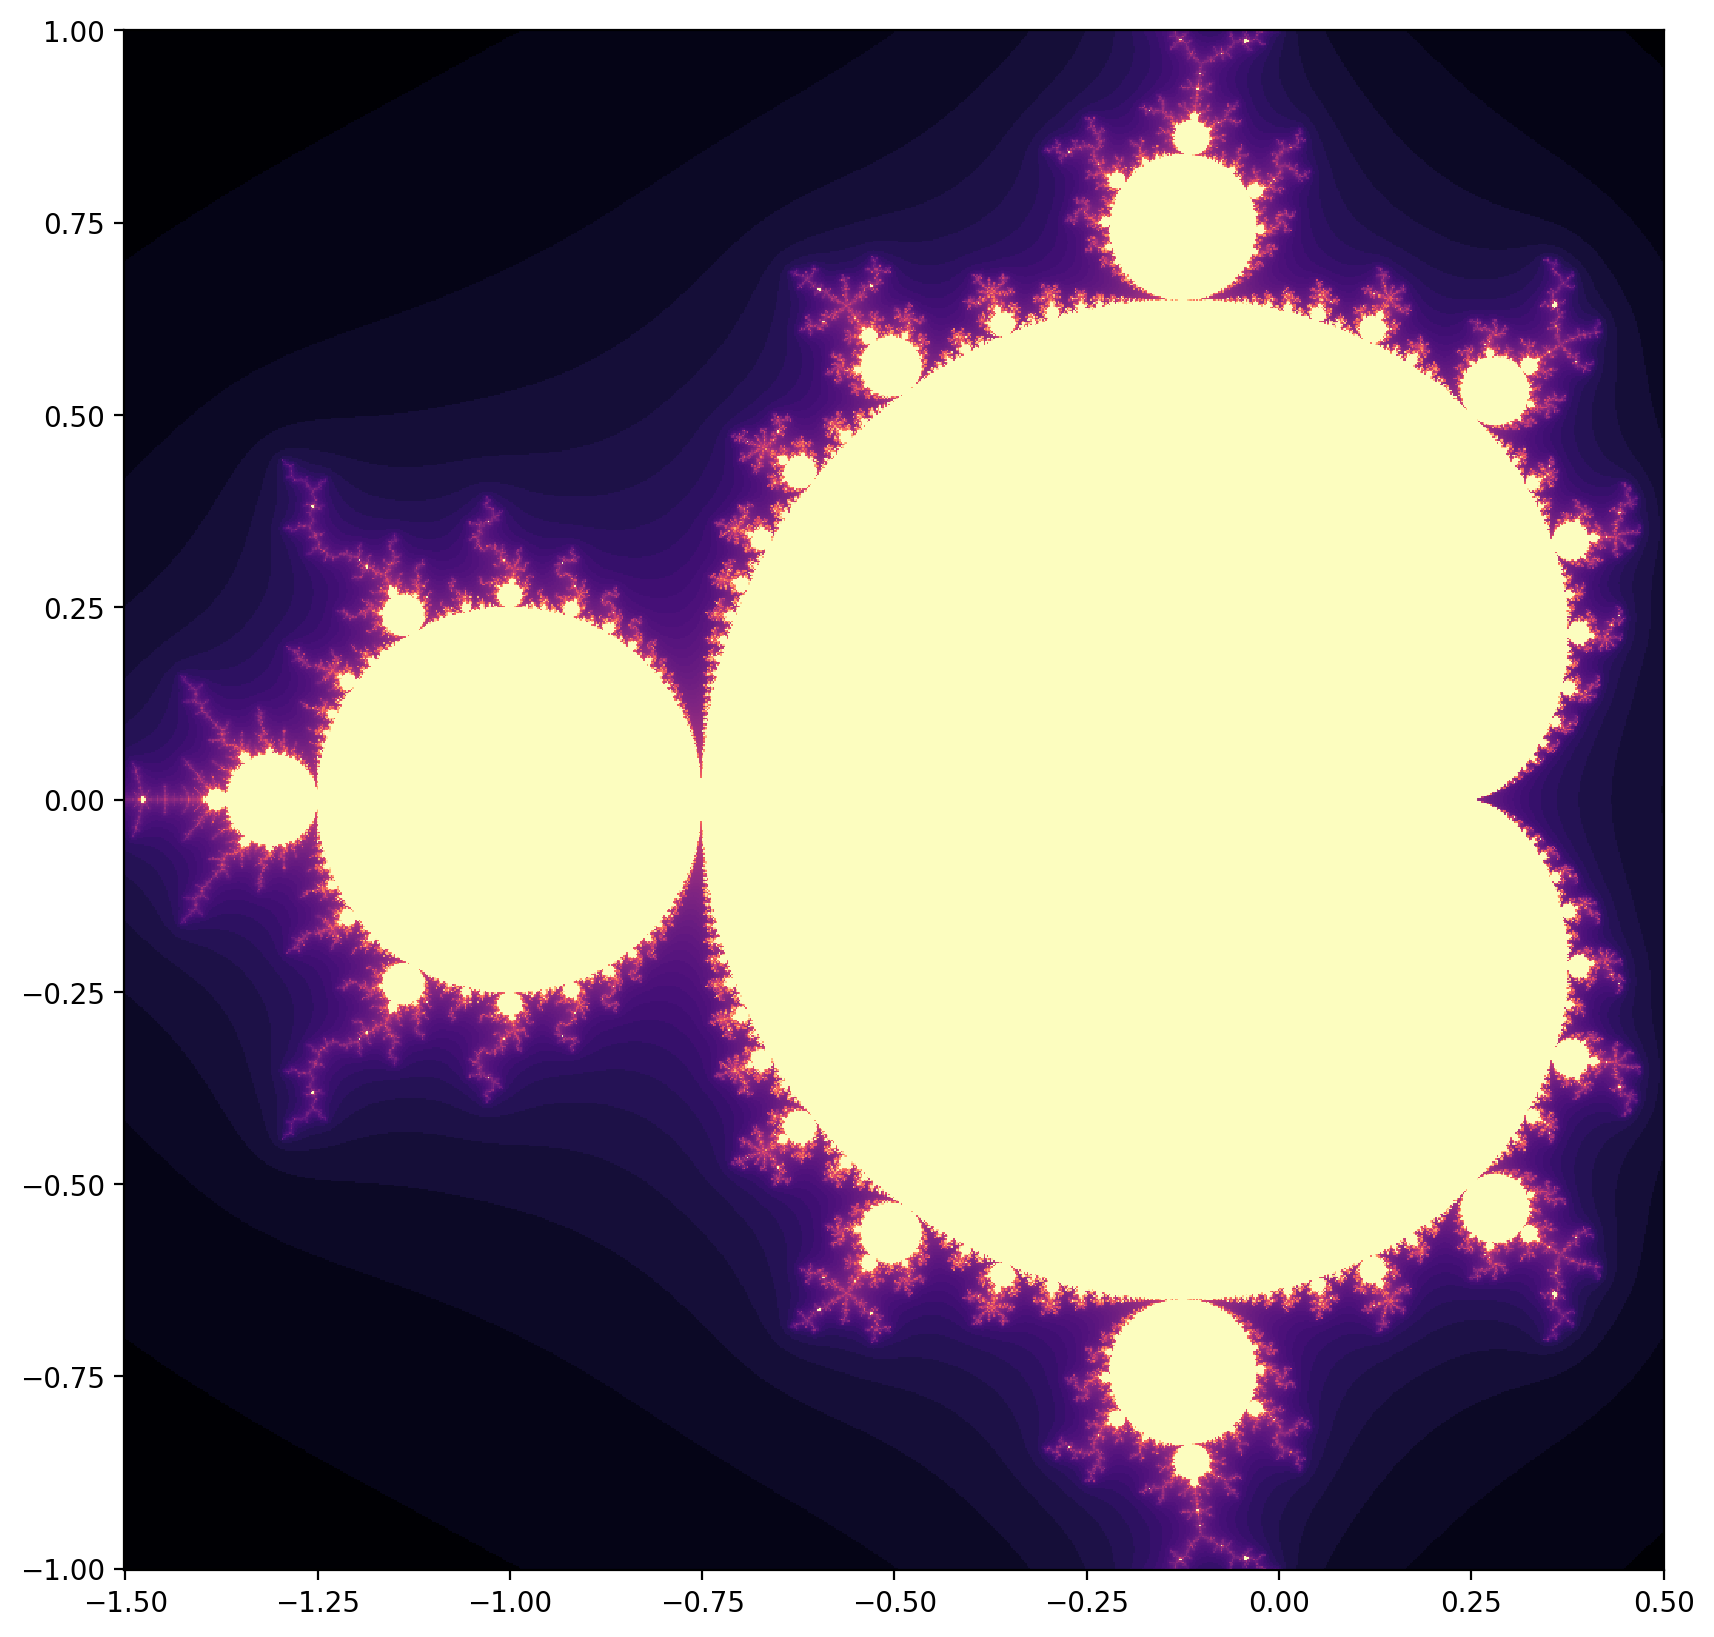

In [62]:
### ÉCRIVEZ ICI

N = 1000

x = np.linspace(-1.5, 0.5, N)
y = np.linspace(-1, 1, N)
x, y = np.meshgrid(x, y)

z = x + y *1j

w = np.zeros_like(z)

steps =np.zeros((N, N))

for i in range(500):
    steps += (np.abs(w)<100)

    w = w**2+z

plt.figure(figsize=(10, 10))

plt.pcolormesh(x, y, np.log(steps), cmap= 'magma')

plt.axis('scaled')
plt.show()

## Un attracteur étrange, ou deux baleines

Voici comment nous pouvons choisir $N=200000$ points au hasard dans le carré $[0,2\pi]\times[0,2\pi]$ et les tracer, en utilisant la coordonnée $y$ comme couleur. **Exécutez la cellule ci-dessous.**

> - La commande `np.random.random(N)` produit un tableau de `N` nombres aléatoires de l'intervalle $[0,1]$.
> - Si cela s'exécute trop lentement, vous pouvez diminuer `N` (au prix d'avoir des images moins belles).
> - `plt.scatter` permet de tracer des points de différentes tailles et couleurs. Nous utilisons la même très petite taille pour chaque point (`s=0.05`; l'option `marker='.'` se marie bien avec des tailles aussi petites). Pour la couleur, nous utilisons le tableau `color`, qui a été défini comme étant `y`. L'option `cmap='hsv'` choisit une gamme de couleurs particulière.

In [ ]:
N = 200000
x = 2*np.pi * np.random.random(N)
y = 2*np.pi * np.random.random(N)
color = y

plt.scatter(x, y, s=0.05, c=color, marker='.', cmap='hsv')
plt.title('Points initiaux')
plt.axis('scaled')
plt.show()

<div style="border: 1px solid gold; padding: 5px">

**Exercice:**

Itérons maintenant la fonction $$\bigl(x,y\bigr)\mapsto\bigl(\sin(a\, y) - \cos(b\, x),\, \sin(c\, x) - \cos(d\, y)\bigr)$$ où
$$a=1,\quad b=2,\quad c=1,\quad d=1.$$

- Appliquez cette transformation aux points que nous avons générés ci-dessus. Visualisez les points résultants comme ci-dessus, en utilisant toujours `c=color` - cela vous aidera à voir quel point a été envoyé où.
- Itérez ceci 10 fois et dessinez l'image après chaque itération; mettez le numéro de l'itération dans le titre de l'image.
- Enfin, dessinez ce qui se passe après la 100ème itération.
- Essayez d'autres choix de $a,b,c,d$, par exemple $1,3,1,1$ (ou tout autre choix). Vous pouvez également modifier complètement la fonction.
</div>

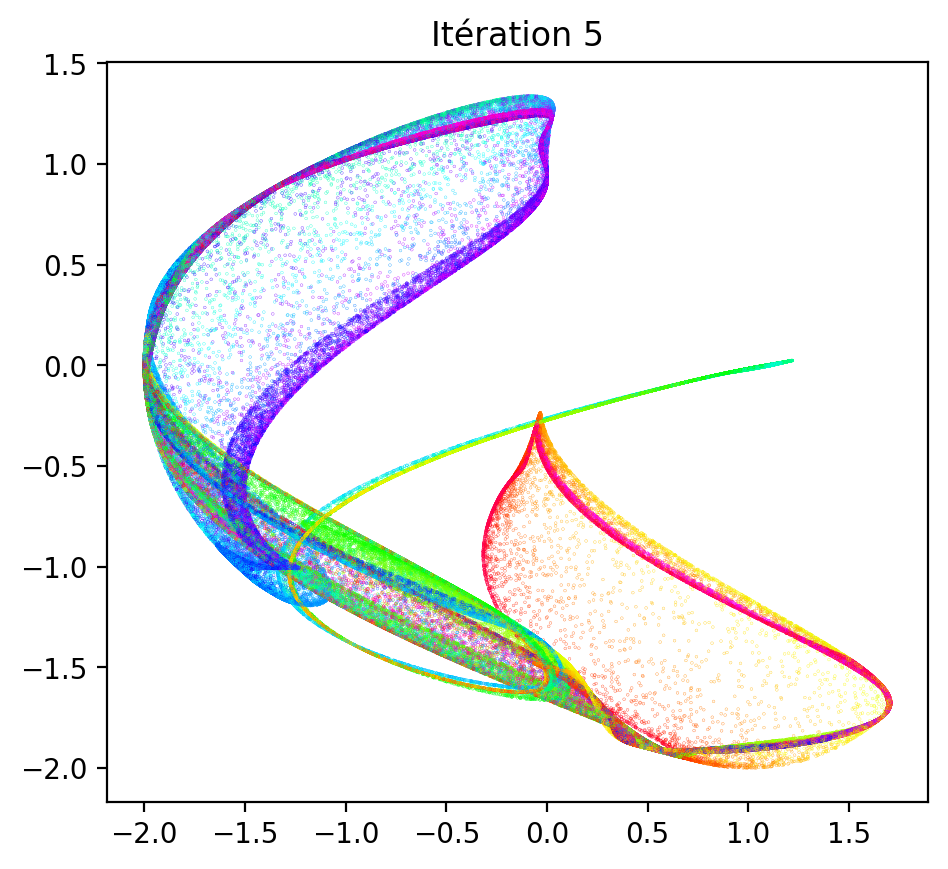

In [69]:
### ÉCRIVEZ ICI

N = 200000

x = 2*np.pi*np.random.random(N)
y = 2*np.pi*np.random.random(N)

color = y

a = 1 
b = 2
c = 1
d = 1

for i in range(1, 101):
    new_x = np.sin(a*y)-np.cos(b*x)
    new_y = np.sin(c*x)- np.cos(d*y)

    x = new_x
    y = new_y

    if i == 5:
        plt.figure()
        plt.scatter(x, y, s=0.05, c=color, marker='.', cmap='hsv')
        plt.title(f'Itération {i}')
        plt.axis('scaled')
        plt.show()
